# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

current_dir = os.path.dirname(os.path.abspath("Incremental-Learning-MycroftMinds"))
parent_dir = os.path.dirname(current_dir)
# Insert the parent directory at the beginning of sys.path if it's not already there.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

## Import external libs and internal models

In [2]:
import time
from typing import Optional, Tuple, Dict, Any, List

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
#from river.drift.binary import DDM, EDDM
from src.bagging import ARFRegressorFODT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_splits_seq_fit_predict
from src.evaluation.baseline import PreviousValueRegressor

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [4]:
HOURLY = True
DATA_FREQUENCY = 'H' if HOURLY else '5min'

In [5]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_hourly_wfv', use_numpy=True)
    features = ['time', 'device_id', 'hour', 'weekday', 'month', 
                 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                 'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                 'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = []

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(649, 43), y=(649,)
First valid split shape: X=(672, 43), y=(672,)

Memory usage:
Train: 6.26 MB
Valid: 1.41 MB
Test: 0.41 MB
Total: 8.08 MB


# Model evaluation

## Hourly granularity

### Baseline model (predict previous value)

In [7]:
update_freq = "1H"
baseline = PreviousValueRegressor()

baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_splits_seq_fit_predict(
    model=baseline,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2535
	MAE: 0.1477
	MAPE: 17.4044%
	Directional Accuracy: 36.0656%
	First-Diff Correlation: -0.0202
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.3479
	MAE: 0.1664
	MAPE: 1.2382%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 0.9991
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.7345
	MAE: 0.5260
	MAPE: 1.6558%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2578
	MAE: 0.1454
	MAPE: 23.4458%
	Directional Accuracy: 38.3010%
	First-Diff Correlation: 0.2243
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.3271
	MAE: 0.1383
	MAPE: 1.1178%
	Directional Accuracy: 92.8571%
	First-Diff Correlation: 0.9996
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.7888
	MAE: 0.5596
	MAPE: 1.8351%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
---------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2448
	MAE: 0.1448
	MAPE: 31.0642%
	Directional Accuracy: 37.4069%
	First-Diff Correlation: -0.0210
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.2440
	MAE: 0.1046
	MAPE: 1.6144%
	Directional Accuracy: 96.4286%
	First-Diff Correlation: 0.9994
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.5621
	MAE: 0.3264
	MAPE: 1.1034%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1543
	MAE: 0.0696
	MAPE: 12.5644%
	Directional Accuracy: 40.1274%
	First-Diff Correlation: 0.4616
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.1261
	MAE: 0.0562
	MAPE: 1.5523%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 0.9999
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.2839
	MAE: 0.2015
	MAPE: 0.4179%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

#### Results

In [8]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2280 ± 0.0407
	MAE: 0.1290 ± 0.0296
	MAPE: 23.9570% ± 7.3836%
	Dir Accuracy: 39.3923% ± 4.6442%
	First-Diff Correlation: 0.1838 ± 0.1970
Daily Metrics:
	RMSE: 0.2624 ± 0.0673
	MAE: 0.1164 ± 0.0326
	MAPE: 1.3658% ± 0.2072%
	Dir Accuracy: 95.9184% ± 3.5348%
	First-Diff Correlation: 0.9995 ± 0.0003
Weekly Metrics:
	RMSE: 0.6121 ± 0.1525
	MAE: 0.4144 ± 0.1132
	MAPE: 1.5435% ± 0.5466%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 0.9733 ± 0.2806
	MAE: 0.9369 ± 0.2661
	MAPE: 3.3684% ± 1.3496%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


#### Validation plots

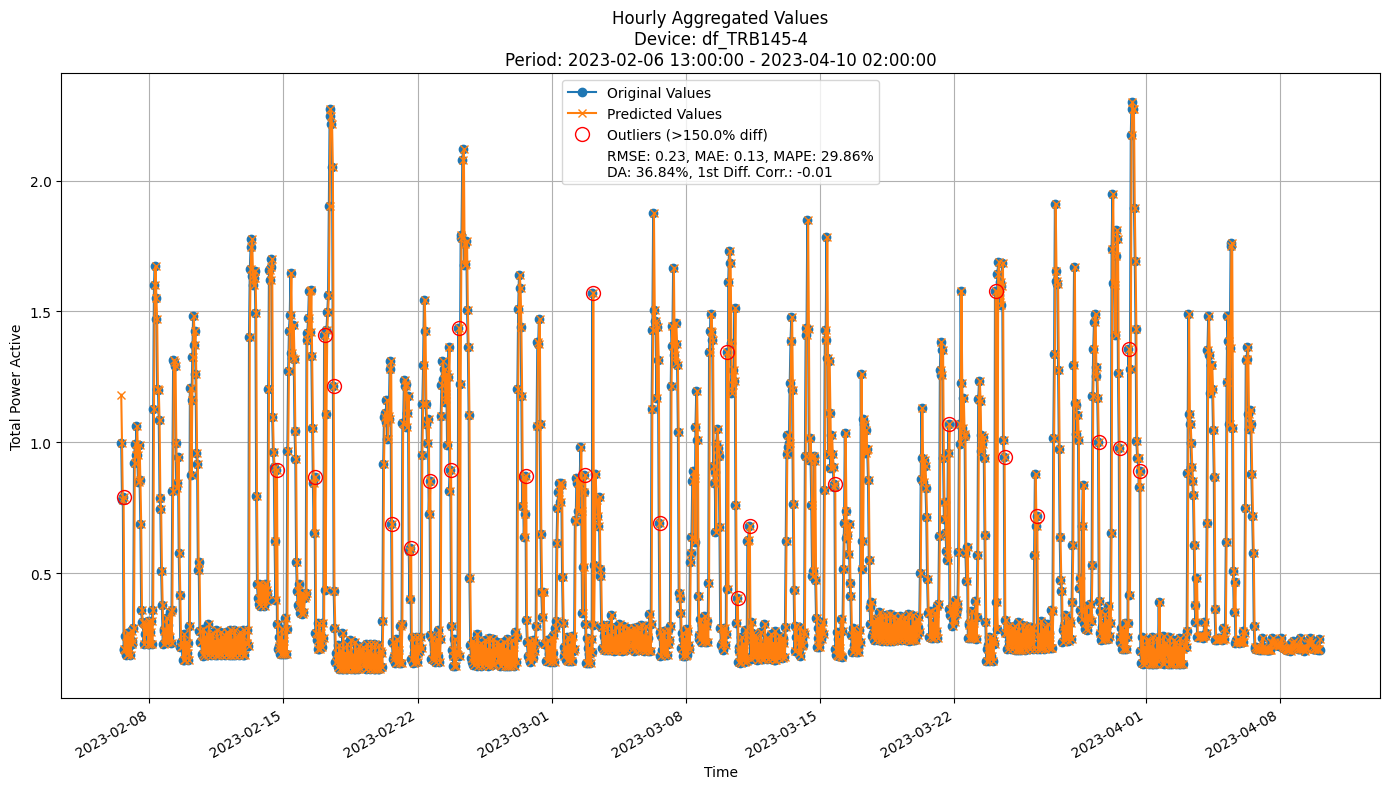

In [9]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [10]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.01,
    subsample=0.8,
    max_depth=6,
    random_state=42)

gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 1.79 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 2.70 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3482
	MAE: 0.2301
	MAPE: 27.6529%
	Directional Accuracy: 55.5887%
	First-Diff Correlation: 0.2436
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.5960
	MAE: 3.8795
	MAPE: 21.1654%
	Directional Accuracy: 75.0000%
	Firs

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 3.71 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 4.63 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3076
	MAE: 0.2171
	MAPE: 42.6263%
	Directional Accuracy: 56.0358%
	First-Diff Correlation: 0.4015
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.0260
	MAE: 2.5278
	MAPE: 20.6638%
	Directional Accuracy: 75.0000%
	Firs

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 11.71 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 12.88 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2263
	MAE: 0.1545
	MAPE: 37.4840%
	Directional Accuracy: 54.6945%
	First-Diff Correlation: 0.3176
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.6473
	MAE: 1.3937
	MAPE: 15.6618%
	Directional Accuracy: 92.8571%
	Fi

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 13.73 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1649
	MAE: 0.1197
	MAPE: 37.1971%
	Directional Accuracy: 55.4140%
	First-Diff Correlation: 0.4113
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.5093
	MAE: 1.2877
	MAPE: 25.8741%
	Directional Accuracy: 85.7143%
	First-Diff Correlation: 0.9851
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 7.1031
	MAE: 5.1507
	MAPE: 27.2372%
	Directional Accuracy: 100.0000%
	First-Di

#### Results

In [11]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1498 ± 0.0225
	MAE: 0.1031 ± 0.0135
	MAPE: 21.4178% ± 3.0083%
	Dir Accuracy: 73.5206% ± 1.6274%
	First-Diff Correlation: 0.8225 ± 0.0714
Daily Metrics:
	RMSE: 1.4884 ± 0.1854
	MAE: 1.2391 ± 0.1446
	MAPE: 11.0395% ± 1.0980%
	Dir Accuracy: 88.5205% ± 3.7217%
	First-Diff Correlation: 0.9943 ± 0.0016
Weekly Metrics:
	RMSE: 4.4955 ± 1.0513
	MAE: 3.6101 ± 0.8590
	MAPE: 3.8997% ± 0.6474%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 14.6017 ± 5.9032
	MAE: 13.4024 ± 5.5116
	MAPE: 3.0165% ± 1.2373%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2450 ± 0.0615
	MAE: 0.1702 ± 0.0404
	MAPE: 38.6482% ± 6.3

#### Feature importance
[WiP] Right now only for the last split and last device

In [12]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.5943921845500145)),
 ('hour', np.float64(0.08886917084971233)),
 ('L2_current_lag_1h', np.float64(0.07192525244996019)),
 ('L2_act_power_lag_1h', np.float64(0.07107288213260735)),
 ('L3_react_power_lag_1h', np.float64(0.036767583077128095)),
 ('month', np.float64(0.013931180942019172)),
 ('powerfactor3_lag_1h', np.float64(0.012754361992107251)),
 ('L2_app_power_lag_1h', np.float64(0.012263424677982897)),
 ('L1_app_power_lag_1h', np.float64(0.010302824449483328)),
 ('L1_act_power_lag_1h', np.float64(0.006141652915243028)),
 ('L3_act_power_lag_1h', np.float64(0.004925153490228159)),
 ('grid_freq_lag_1h', np.float64(0.0046450919333752986)),
 ('L3_react_power_lag_24h', np.float64(0.004565227564230447)),
 ('L1_react_power_lag_24h', np.float64(0.00454232057276003)),
 ('L3_app_power_lag_1h', np.float64(0.004420363660290429)),
 ('powerfactor2_lag_24h', np.float64(0.004363829136757241)),
 ('L2_act_power_lag_24h', np.float64(0.004192033404760283)),
 ('weekday'

#### Training plots

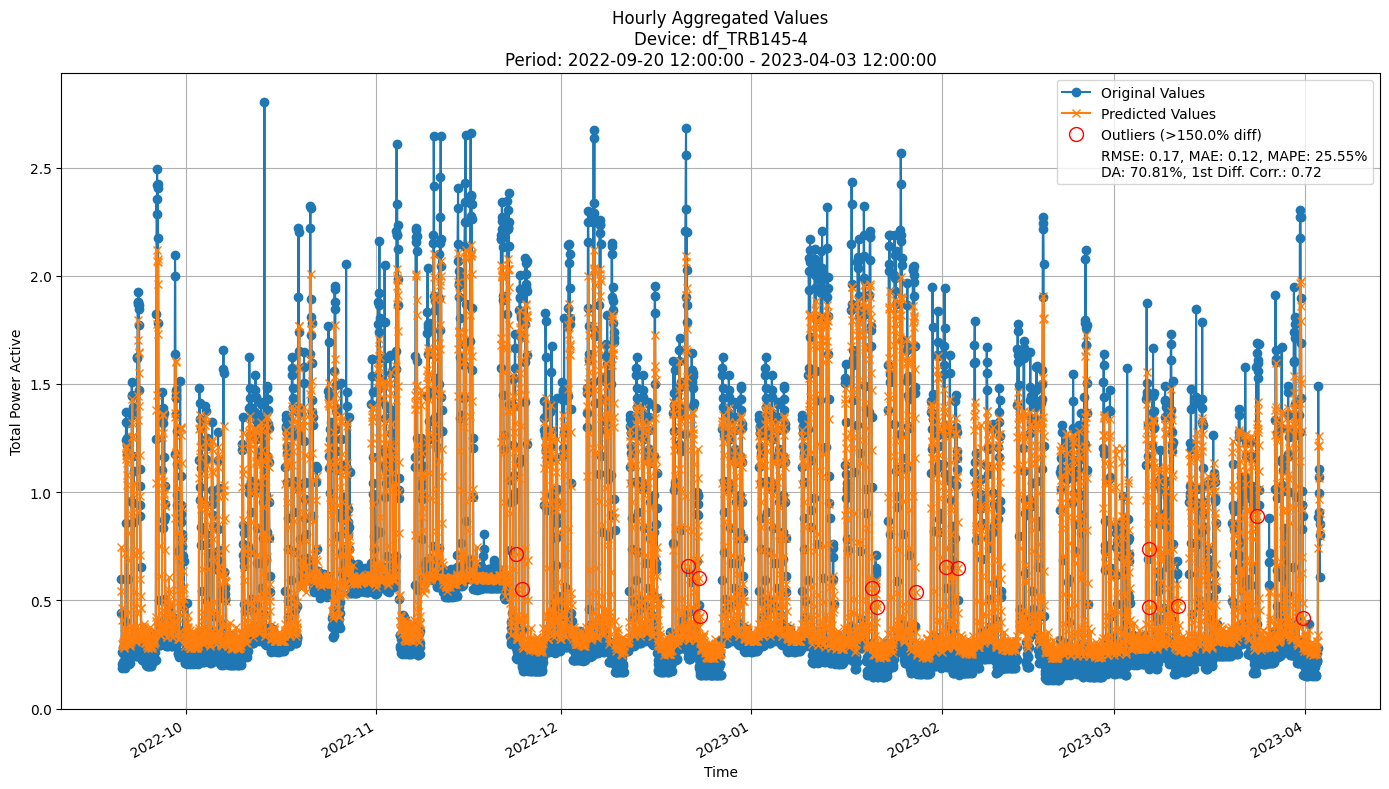

In [13]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

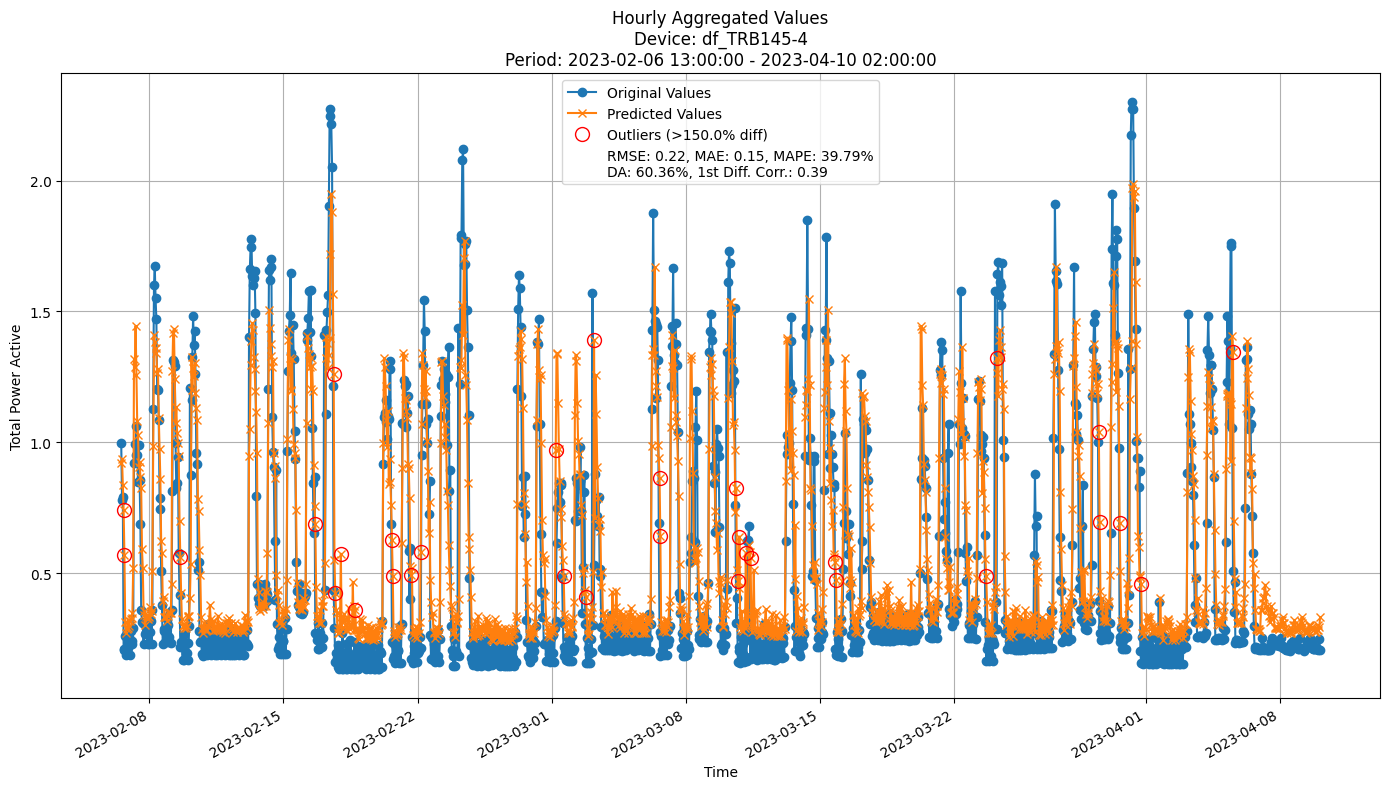

In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# 0.22, 0.15, 39.79, 60.39%, 0.39

### Random Forest model

In [15]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=4,
    max_features=0.8,
    random_state=42, 
    n_jobs=-1)

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 0.12 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 0.16 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3245
	MAE: 0.1964
	MAPE: 21.2100%
	Directional Accuracy: 55.8867%
	First-Diff Correlation: 0.2723
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.1727
	MAE: 3.2215
	MAPE: 15.9071%
	Directional Accuracy: 78.5714%
	Firs

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 0.15 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 0.16 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2865
	MAE: 0.1745
	MAPE: 29.9529%
	Directional Accuracy: 53.8003%
	First-Diff Correlation: 0.3476
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.4516
	MAE: 2.0109
	MAPE: 13.6949%
	Directional Accuracy: 78.5714%
	Firs

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 0.36 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 0.35 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2385
	MAE: 0.1486
	MAPE: 32.3394%
	Directional Accuracy: 54.9925%
	First-Diff Correlation: 0.3601
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.8463
	MAE: 1.4042
	MAPE: 13.1446%
	Directional Accuracy: 89.2857%
	Firs

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 0.38 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1555
	MAE: 0.0837
	MAPE: 21.6022%
	Directional Accuracy: 43.9490%
	First-Diff Correlation: 0.4294
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.2097
	MAE: 1.0438
	MAPE: 13.9619%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 0.9994
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 5.8558
	MAE: 4.1750
	MAPE: 11.5596%
	Directional Accuracy: 100.0000%
	First-Di

#### Results

In [16]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2221 ± 0.0148
	MAE: 0.1267 ± 0.0092
	MAPE: 22.1472% ± 2.0063%
	Dir Accuracy: 60.8511% ± 2.9815%
	First-Diff Correlation: 0.4859 ± 0.0565
Daily Metrics:
	RMSE: 1.7668 ± 0.1502
	MAE: 1.3197 ± 0.1091
	MAPE: 9.8361% ± 0.5326%
	Dir Accuracy: 86.2758% ± 3.7728%
	First-Diff Correlation: 0.9783 ± 0.0024
Weekly Metrics:
	RMSE: 6.2770 ± 1.4383
	MAE: 4.8404 ± 1.0919
	MAPE: 5.2972% ± 0.9092%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 19.7357 ± 8.0124
	MAE: 17.9420 ± 7.0945
	MAPE: 4.0417% ± 1.5877%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2221 ± 0.0148
	MAE: 0.1267 ± 0.0092
	MAPE: 22.1472% ± 2.00

#### Feature importance
[WiP] Right now only for the last split and last device

In [17]:
feat_imps = sorted(
    zip(features[2:], rf.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.5762642336881951)),
 ('L1_app_power_lag_1h', np.float64(0.10568487077227992)),
 ('hour', np.float64(0.07371084921967604)),
 ('L2_current_lag_1h', np.float64(0.06284728388419433)),
 ('L2_act_power_lag_1h', np.float64(0.060075330591458746)),
 ('L3_react_power_lag_1h', np.float64(0.04234170230657086)),
 ('L1_act_power_lag_1h', np.float64(0.028437470118502218)),
 ('L2_app_power_lag_1h', np.float64(0.024095446207157485)),
 ('powerfactor3_lag_1h', np.float64(0.0029458156494507758)),
 ('month', np.float64(0.0026329251359712763)),
 ('L3_app_power_lag_1h', np.float64(0.0024065417105137645)),
 ('L3_act_power_lag_1h', np.float64(0.0022050371920968835)),
 ('L2_current_lag_24h', np.float64(0.0019331762146278337)),
 ('L1_react_power_lag_24h', np.float64(0.0018648501384058774)),
 ('L3_act_power_lag_24h', np.float64(0.001423267116350017)),
 ('L1_app_power_lag_24h', np.float64(0.0014062037837172087)),
 ('L1_act_power_lag_24h', np.float64(0.0014000363703803584)),
 ('L

#### Training plots
Plot only the last period of predictions

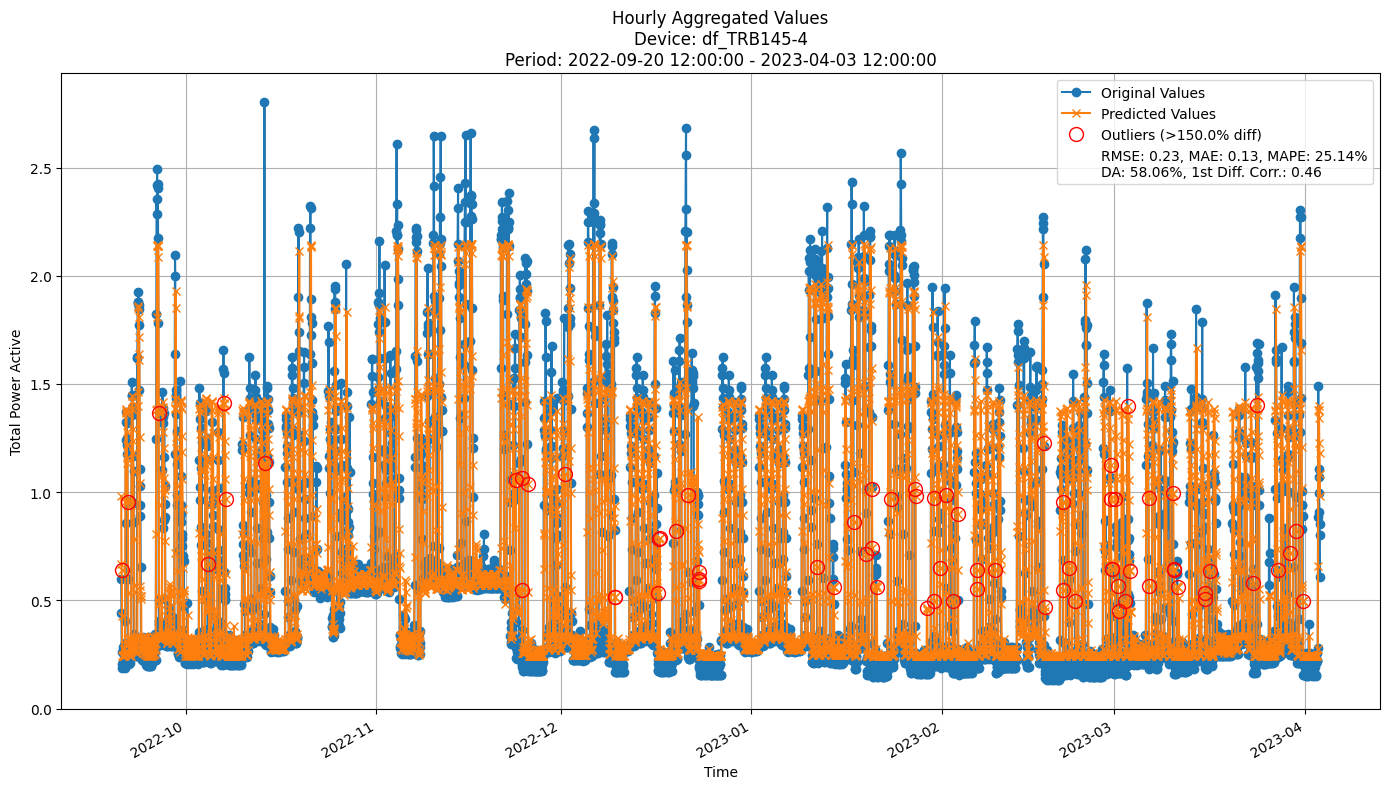

In [18]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

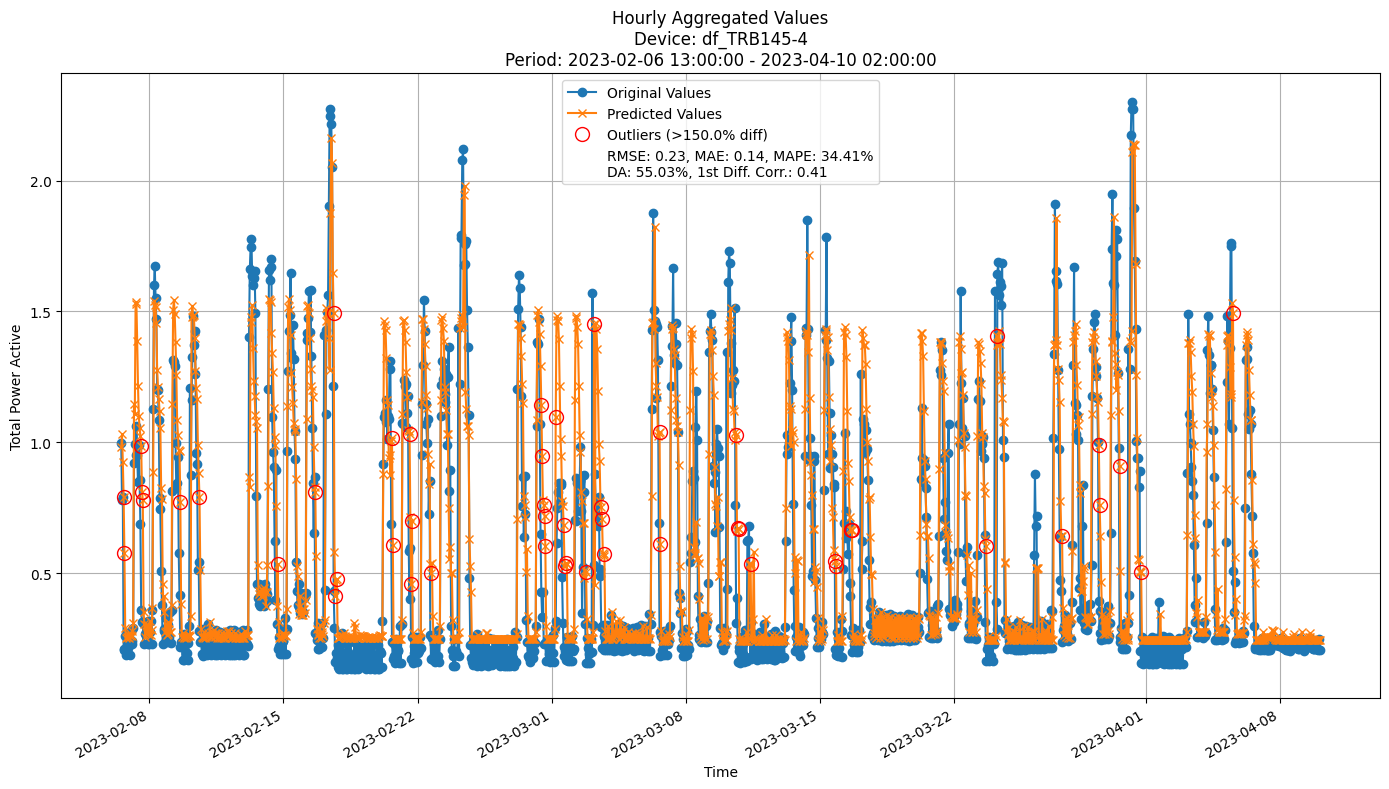

In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [20]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

grace_period = 10
delta = 0.5
max_depth = 10
tau = 0.05

hoef = HoeffdingTreeRegressor(
        max_depth=max_depth,
        grace_period=grace_period,
        delta=delta,
        tau=tau,
        leaf_prediction="mean"
    )

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_splits_seq_fit_predict(
    model=hoef, 
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3746
	MAE: 0.2556
	MAPE: 29.1036%
	Directional Accuracy: 45.3055%
	First-Diff Correlation: 0.2171
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5.1078
	MAE: 4.0082
	MAPE: 20.1554%
	Directional Accuracy: 75.0000%
	First-Diff Correlation: 0.8753
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 21.6977
	MAE: 17.8734
	MAPE: 18.1733%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3566
	MAE: 0.2247
	MAPE: 33.0720%
	Directional Accuracy: 52.0119%
	First-Diff Correlation: 0.2745
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.8259
	MAE: 3.0232
	MAPE: 18.4079%
	Directional Accuracy: 64.2857%
	First-Diff Correlation: 0.9106
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 9.4907
	MAE: 7.4224
	MAPE: 6.5978%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2995
	MAE: 0.1876
	MAPE: 36.9397%
	Directional Accuracy: 49.4784%
	First-Diff Correlation: 0.2496
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.7277
	MAE: 2.2248
	MAPE: 18.7581%
	Directional Accuracy: 85.7143%
	First-Diff Correlation: 0.9136
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 11.7877
	MAE: 10.2484
	MAPE: 17.0823%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1994
	MAE: 0.1174
	MAPE: 28.7214%
	Directional Accuracy: 57.3248%
	First-Diff Correlation: 0.2887
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.7537
	MAE: 1.5365
	MAPE: 24.9960%
	Directional Accuracy: 71.4286%
	First-Diff Correlation: 0.9343
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 5.9390
	MAE: 4.3335
	MAPE: 26.9448%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-------------------------------------

#### Results

In [21]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2769 ± 0.0336
	MAE: 0.1652 ± 0.0247
	MAPE: 28.4640% ± 5.7028%
	Dir Accuracy: 36.6377% ± 6.1702%
	First-Diff Correlation: 0.3328 ± 0.0960
Daily Metrics:
	RMSE: 2.6302 ± 0.6186
	MAE: 2.0575 ± 0.5088
	MAPE: 14.6692% ± 4.4945%
	Dir Accuracy: 76.5479% ± 4.1340%
	First-Diff Correlation: 0.9250 ± 0.0506
Weekly Metrics:
	RMSE: 9.0415 ± 1.6558
	MAE: 7.2159 ± 1.3220
	MAPE: 7.9245% ± 1.8859%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 27.6639 ± 10.4680
	MAE: 25.8932 ± 9.6501
	MAPE: 6.1459% ± 2.1795%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2930 ± 0.0571
	MAE: 0.1852 ± 0.0426
	MAPE: 33.5538% ± 4.

#### Training plots
Plot only the last period of predictions

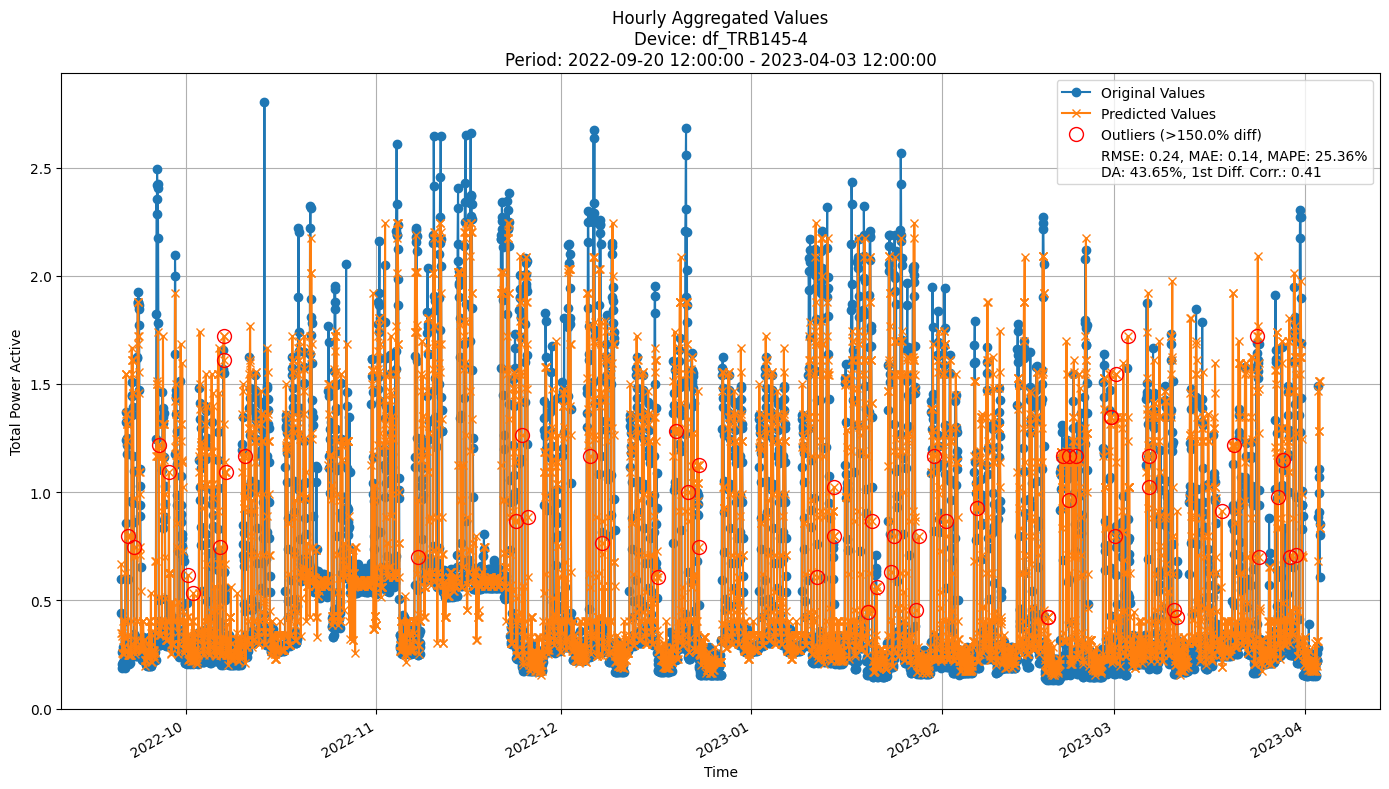

In [22]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

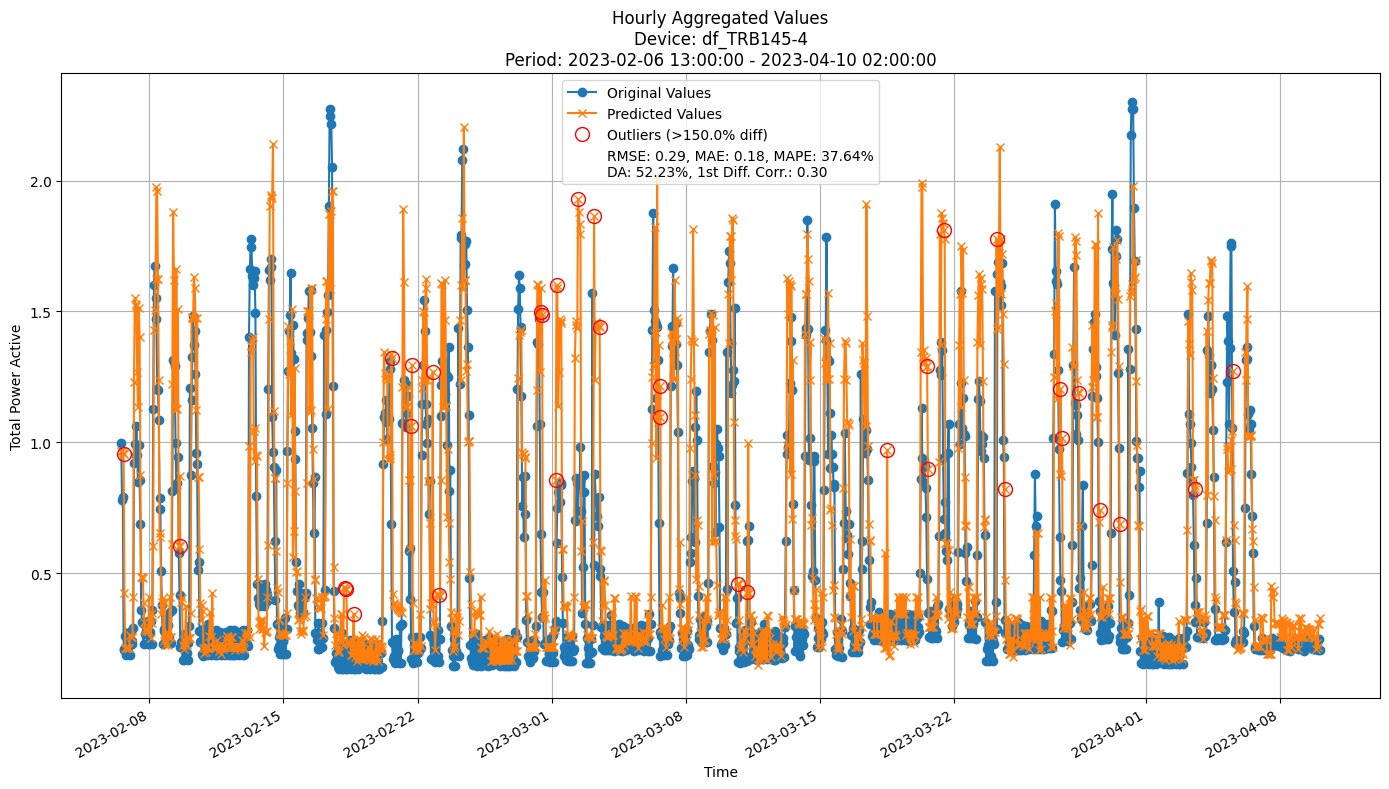

In [23]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [24]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
max_features = 0.8
grace_period = 10
split_confidence = 0.5
depth = 10
tau = 0.01

arf_hf = ARFRegressor(
        n_models=n_models,
        max_features=max_features,
        aggregation_method='median',
        grace_period=grace_period,
        max_depth=depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf_hf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3631
	MAE: 0.2355
	MAPE: 27.3743%
	Directional Accuracy: 52.1610%
	First-Diff Correlation: 0.3317
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5.4454
	MAE: 4.2911
	MAPE: 22.1976%
	Directional Accuracy: 64.2857%
	First-Diff Correlation: 0.7641
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 18.9809
	MAE: 17.0045
	MAPE: 18.9849%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3245
	MAE: 0.2214
	MAPE: 39.9123%
	Directional Accuracy: 57.9732%
	First-Diff Correlation: 0.4104
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.9443
	MAE: 3.1778
	MAPE: 23.2682%
	Directional Accuracy: 67.8571%
	First-Diff Correlation: 0.9482
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 9.8262
	MAE: 6.0751
	MAPE: 5.7340%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2498
	MAE: 0.1676
	MAPE: 37.3576%
	Directional Accuracy: 51.8629%
	First-Diff Correlation: 0.3531
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.3846
	MAE: 1.9652
	MAPE: 18.5437%
	Directional Accuracy: 89.2857%
	First-Diff Correlation: 0.9390
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 10.8421
	MAE: 9.6257
	MAPE: 13.3548%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1904
	MAE: 0.1279
	MAPE: 40.8609%
	Directional Accuracy: 59.2357%
	First-Diff Correlation: 0.4171
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.2832
	MAE: 1.8568
	MAPE: 33.6604%
	Directional Accuracy: 57.1429%
	First-Diff Correlation: 0.9522
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 10.2775
	MAE: 7.4273
	MAPE: 35.5236%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
------------------------------------

#### Results

In [25]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2586 ± 0.0565
	MAE: 0.1637 ± 0.0445
	MAPE: 31.6056% ± 11.1158%
	Dir Accuracy: 58.5306% ± 7.2030%
	First-Diff Correlation: 0.4946 ± 0.1244
Daily Metrics:
	RMSE: 3.1903 ± 0.9528
	MAE: 2.4899 ± 0.8054
	MAPE: 20.5581% ± 9.5556%
	Dir Accuracy: 76.8486% ± 5.8319%
	First-Diff Correlation: 0.8792 ± 0.1838
Weekly Metrics:
	RMSE: 11.5828 ± 2.9687
	MAE: 9.4155 ± 2.8194
	MAPE: 10.6713% ± 3.9050%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 38.9085 ± 18.8850
	MAE: 35.8407 ± 18.6605
	MAPE: 8.1572% ± 4.3419%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2648 ± 0.0614
	MAE: 0.1745 ± 0.0421
	MAPE: 36.3762% 

#### Training plots

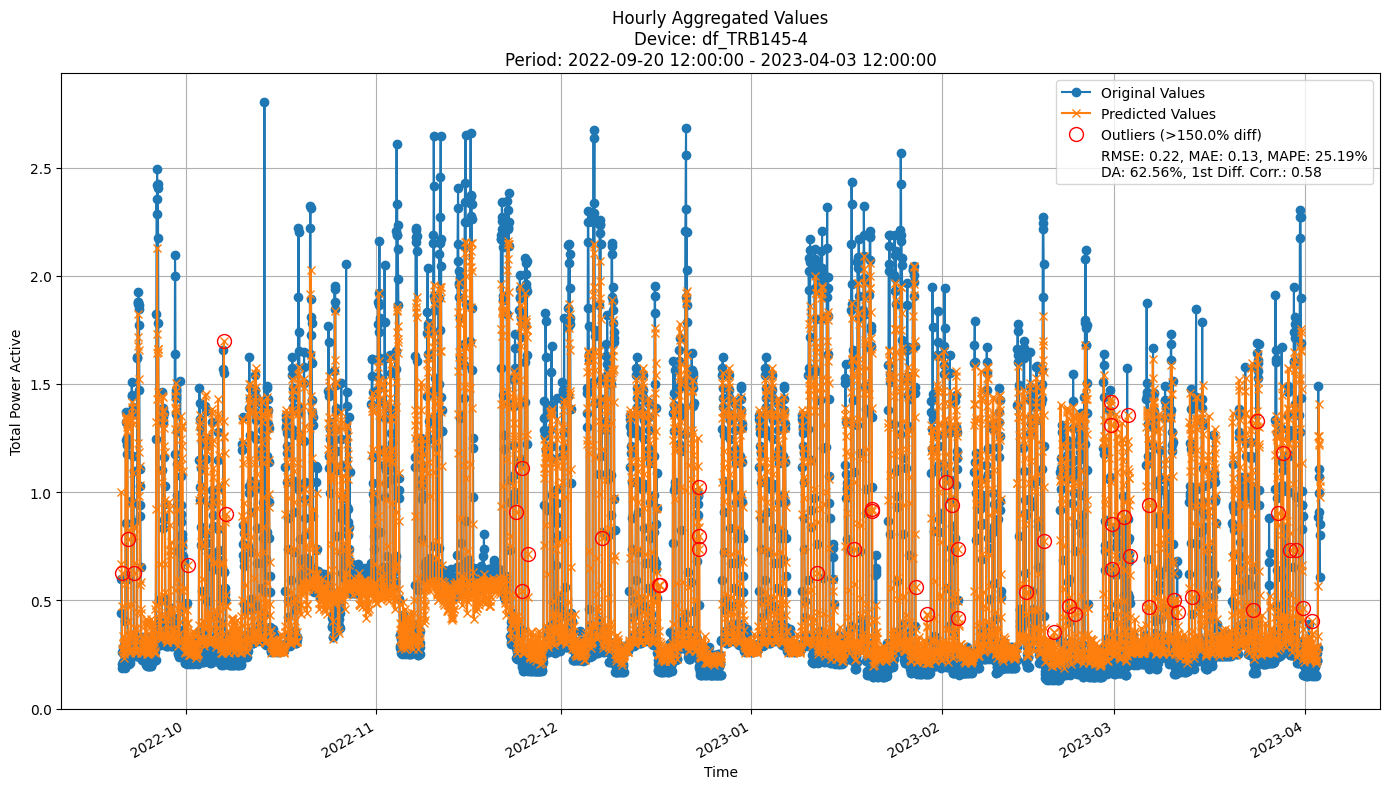

In [26]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

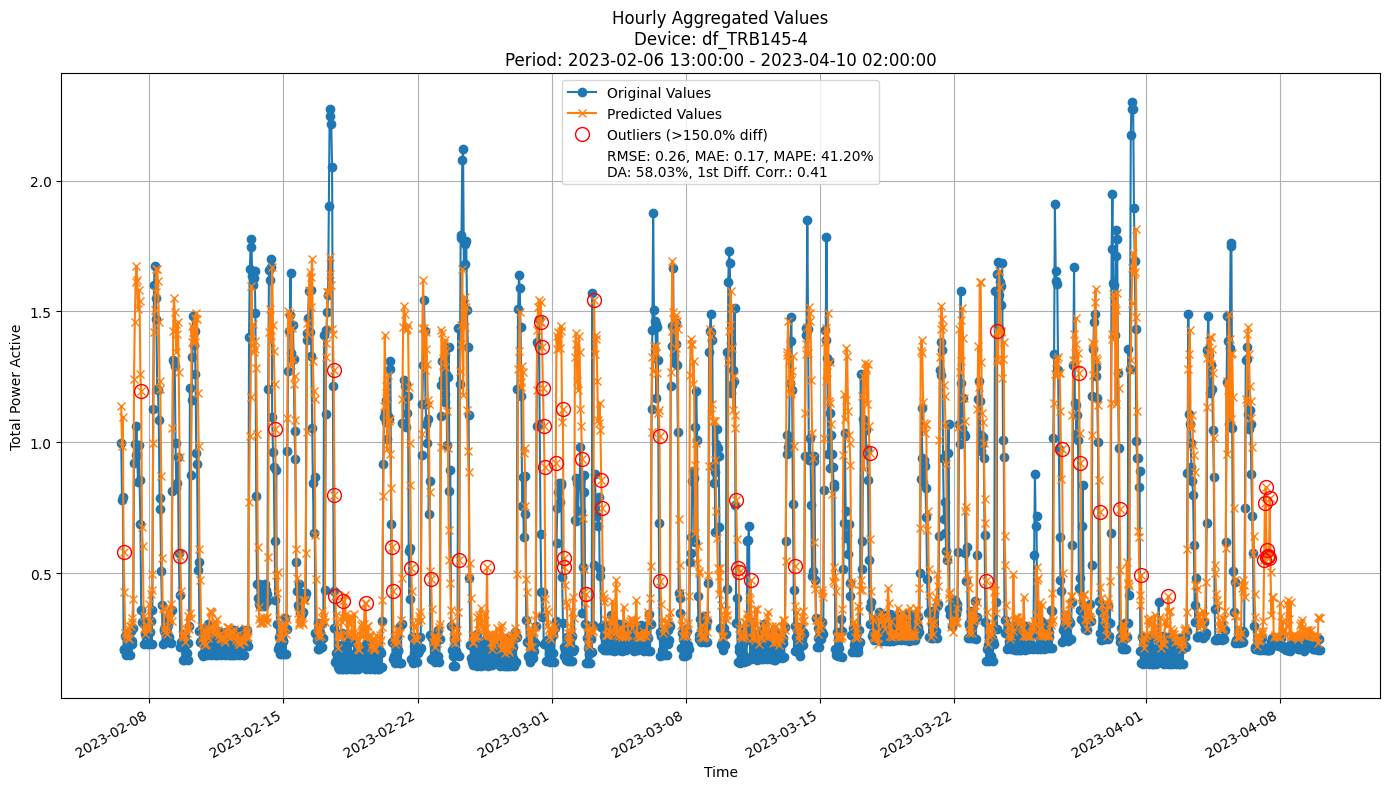

In [27]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [28]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.001
depth = 100
eagerness = 100
fodt = fastodt.FastODT(
        depth=depth,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf',
        eagerness = eagerness
    )

fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5499
	MAE: 0.3876
	MAPE: 40.1311%
	Directional Accuracy: 49.3294%
	First-Diff Correlation: 0.1848
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 9.6246
	MAE: 8.0389
	MAPE: 37.5869%
	Directional Accuracy: 60.7143%
	First-Diff Correlation: 0.5035
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 47.1381
	MAE: 43.0813
	MAPE: 39.8043%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5903
	MAE: 0.4147
	MAPE: 59.5562%
	Directional Accuracy: 48.4352%
	First-Diff Correlation: 0.1622
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 9.2391
	MAE: 7.7388
	MAPE: 49.1818%
	Directional Accuracy: 57.1429%
	First-Diff Correlation: 0.7162
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 35.2714
	MAE: 30.3341
	MAPE: 26.7680%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3156
	MAE: 0.2333
	MAPE: 60.4846%
	Directional Accuracy: 52.7571%
	First-Diff Correlation: 0.2227
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.8874
	MAE: 3.1436
	MAPE: 35.7010%
	Directional Accuracy: 82.1429%
	First-Diff Correlation: 0.7661
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 6.0549
	MAE: 5.2493
	MAPE: 6.7558%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2916
	MAE: 0.2348
	MAPE: 81.7487%
	Directional Accuracy: 45.2229%
	First-Diff Correlation: 0.3303
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.2116
	MAE: 3.1218
	MAPE: 66.8211%
	Directional Accuracy: 85.7143%
	First-Diff Correlation: 0.7663
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 12.5630
	MAE: 9.2205
	MAPE: 65.3366%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
------------------------------------

#### Results

In [29]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4253 ± 0.0258
	MAE: 0.2955 ± 0.0186
	MAPE: 51.7834% ± 3.3534%
	Dir Accuracy: 49.3171% ± 9.4239%
	First-Diff Correlation: 0.3145 ± 0.0179
Daily Metrics:
	RMSE: 6.5780 ± 0.6940
	MAE: 5.3948 ± 0.5466
	MAPE: 40.5002% ± 1.7044%
	Dir Accuracy: 76.3530% ± 6.3045%
	First-Diff Correlation: 0.7814 ± 0.1673
Weekly Metrics:
	RMSE: 25.8921 ± 7.3969
	MAE: 19.9827 ± 5.6116
	MAPE: 17.7150% ± 3.3490%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 99.5931 ± 34.2036
	MAE: 75.8247 ± 24.7937
	MAPE: 14.5066% ± 3.6813%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4292 ± 0.1194
	MAE: 0.3145 ± 0.0762
	MAPE: 65.4404%

#### Training plots


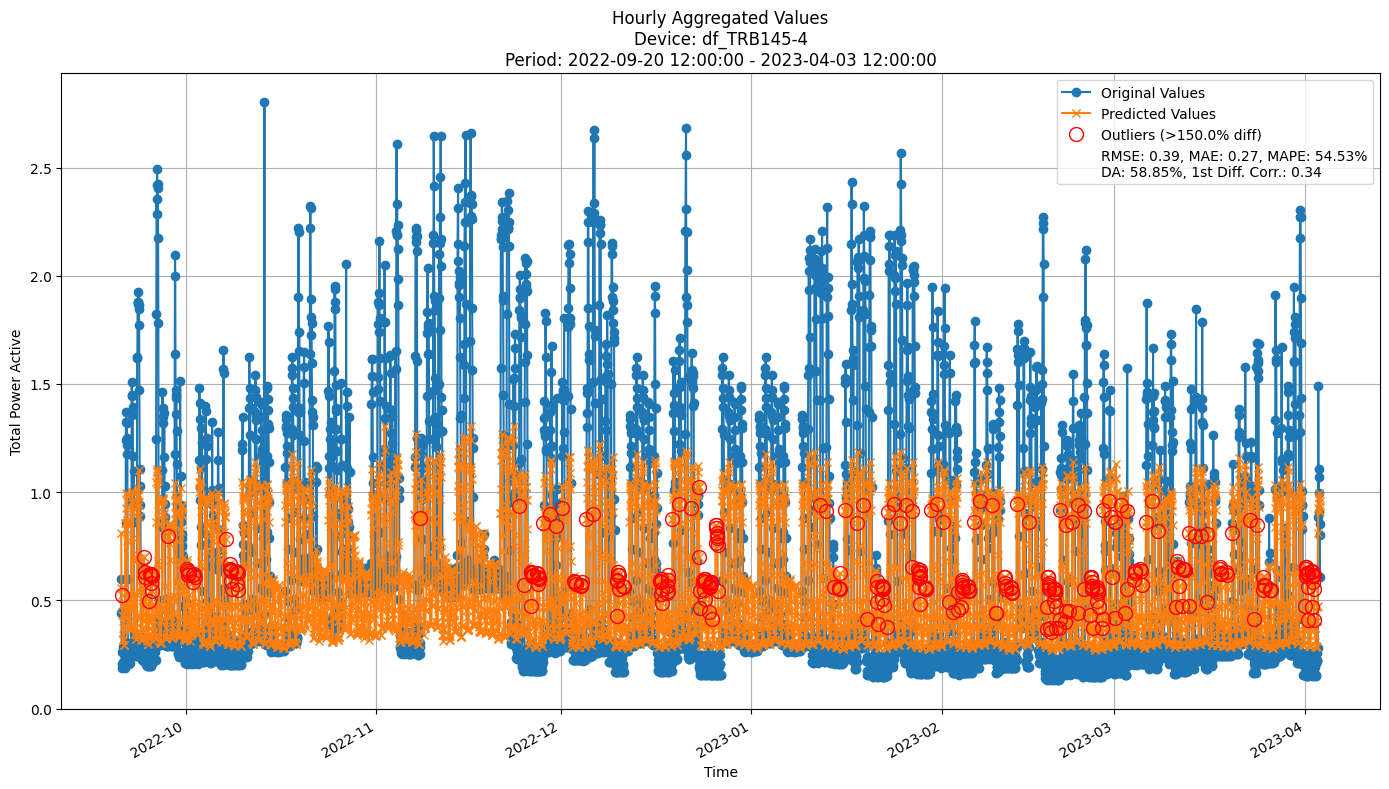

In [30]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

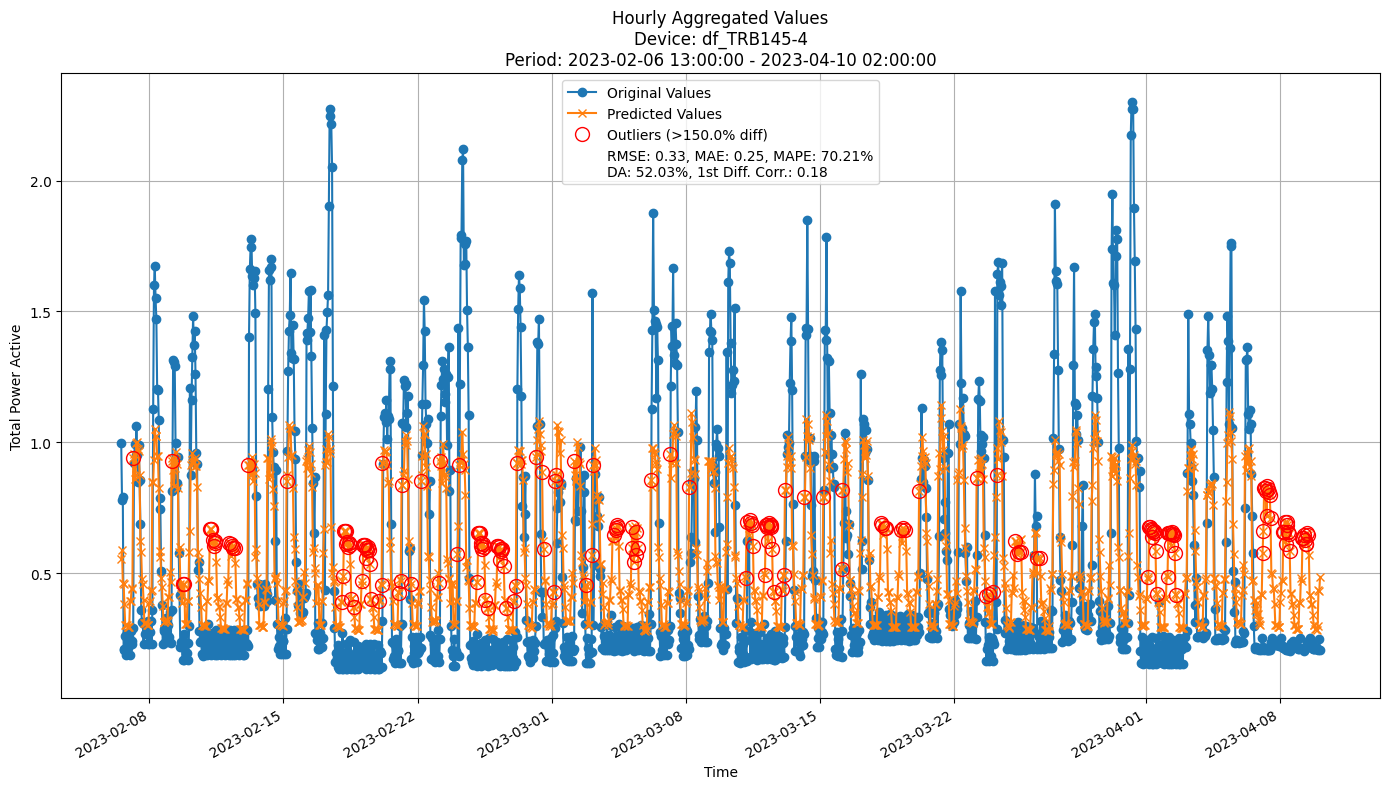

In [31]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [32]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 20
grace_period = 0
aggregation_method = "mean"
split_confidence = 0.005
tau = 0.01
max_depth = 100
eagerness = 200

arf = ARFRegressorFODT(
        n_models=n_models,
        aggregation_method=aggregation_method,
        grace_period=grace_period,
        max_depth=max_depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
        max_feature=0.7,
        eagerness=eagerness,
    )

arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5107
	MAE: 0.3407
	MAPE: 38.2999%
	Directional Accuracy: 55.4396%
	First-Diff Correlation: 0.2891
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 7.8331
	MAE: 6.5766
	MAPE: 34.3193%
	Directional Accuracy: 67.8571%
	First-Diff Correlation: 0.4102
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 29.9291
	MAE: 26.5969
	MAPE: 27.6717%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5513
	MAE: 0.4300
	MAPE: 86.1609%
	Directional Accuracy: 57.5261%
	First-Diff Correlation: 0.4453
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 7.4879
	MAE: 6.1501
	MAPE: 53.1440%
	Directional Accuracy: 53.5714%
	First-Diff Correlation: 0.6429
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 12.7659
	MAE: 10.5515
	MAPE: 9.8147%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3075
	MAE: 0.2363
	MAPE: 63.7781%
	Directional Accuracy: 55.7377%
	First-Diff Correlation: 0.4197
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.8936
	MAE: 3.1796
	MAPE: 37.7176%
	Directional Accuracy: 85.7143%
	First-Diff Correlation: 0.7835
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 8.7580
	MAE: 7.5427
	MAPE: 11.1832%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2339
	MAE: 0.1943
	MAPE: 62.0435%
	Directional Accuracy: 54.7771%
	First-Diff Correlation: 0.5896
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.7579
	MAE: 2.2390
	MAPE: 45.3216%
	Directional Accuracy: 85.7143%
	First-Diff Correlation: 0.9084
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 7.5402
	MAE: 5.5151
	MAPE: 36.2515%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-------------------------------------

#### Results

In [33]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4075 ± 0.0286
	MAE: 0.3016 ± 0.0335
	MAPE: 64.8177% ± 10.7060%
	Dir Accuracy: 61.3031% ± 1.6145%
	First-Diff Correlation: 0.4273 ± 0.0717
Daily Metrics:
	RMSE: 6.1152 ± 0.5996
	MAE: 4.9485 ± 0.5405
	MAPE: 44.8040% ± 5.5449%
	Dir Accuracy: 68.5118% ± 4.2904%
	First-Diff Correlation: 0.7794 ± 0.0816
Weekly Metrics:
	RMSE: 22.5527 ± 5.7894
	MAE: 18.0761 ± 4.1857
	MAPE: 18.5410% ± 3.4095%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 84.3334 ± 25.1146
	MAE: 71.1188 ± 19.0427
	MAPE: 16.1021% ± 3.9867%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3898 ± 0.1082
	MAE: 0.3116 ± 0.0793
	MAPE: 79.5971

#### Training plots


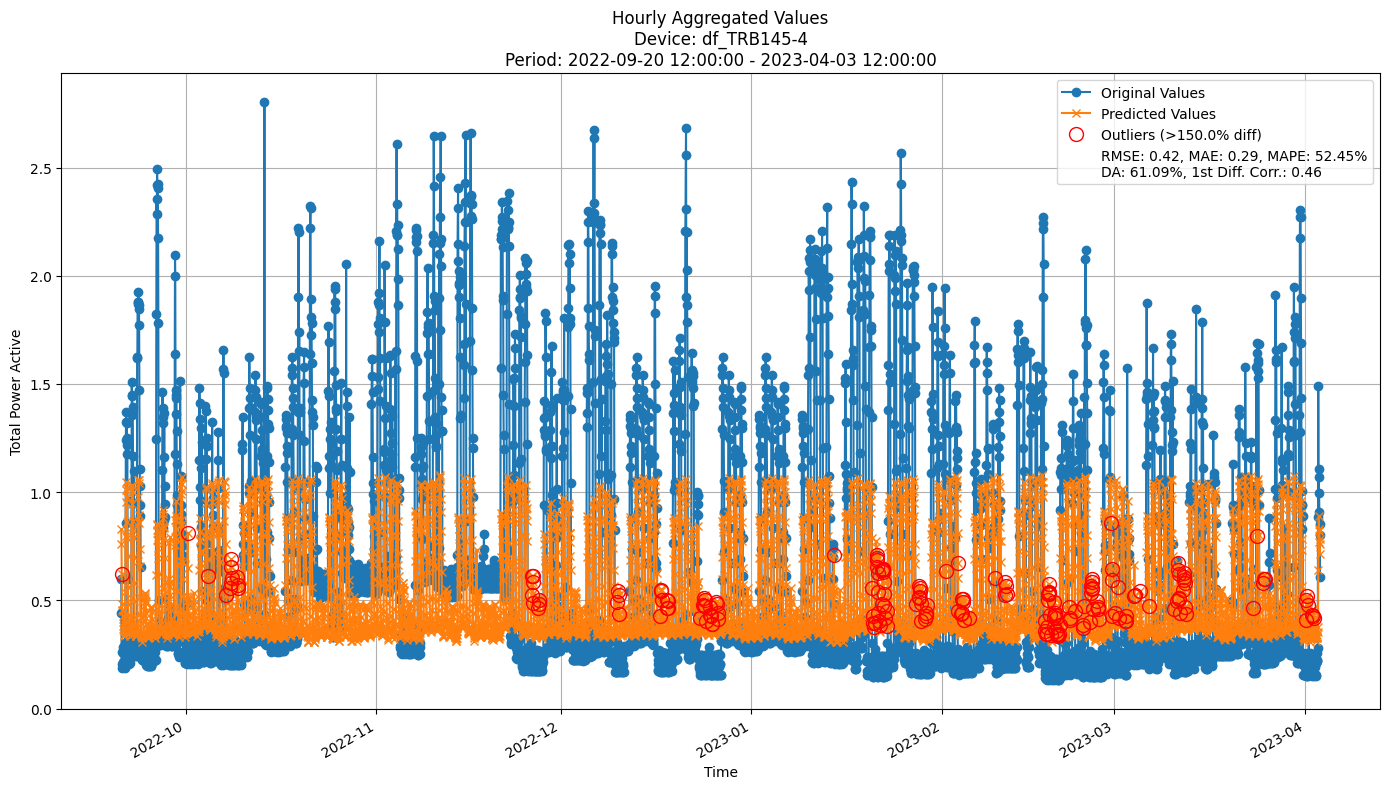

In [34]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

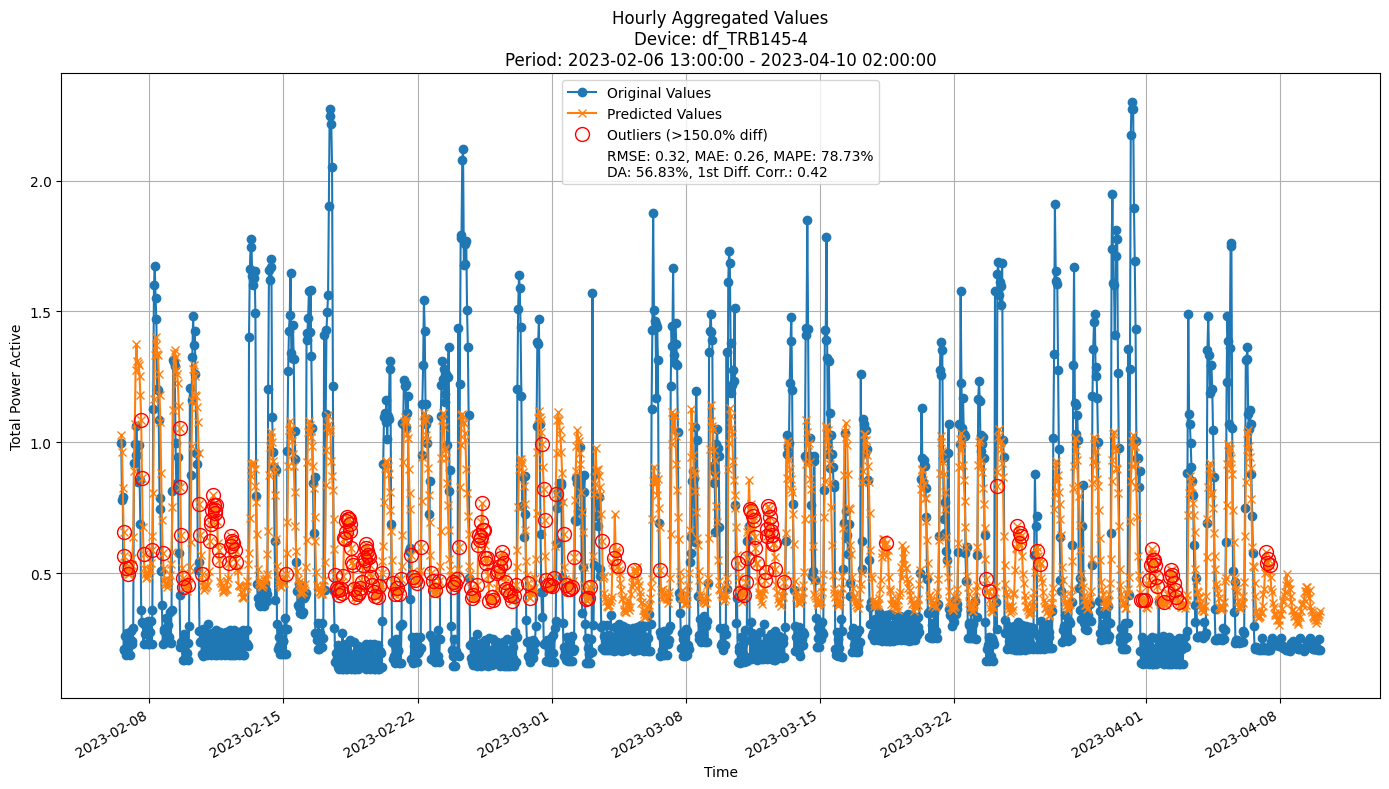

In [35]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [45]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:
split_confidence_hf = 0.001
n_trees = 10
depth = 100
grace_period = 10
max_feature = 1.0
eagerness = 1000
incb = IncubationBoost(
    fastodt.FastODT,
    length=n_trees,
    incubationMode = "DEFAULT",
    baseLearnerOptions = (depth, grace_period, split_confidence, "hf", max_features, eagerness),
    verbose=False
    )

incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5997
	MAE: 0.4174
	MAPE: 41.5649%
	Directional Accuracy: 54.5455%
	First-Diff Correlation: 0.2306
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 10.7623
	MAE: 9.2417
	MAPE: 43.4533%
	Directional Accuracy: 50.0000%
	First-Diff Correlation: 0.3718
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 55.2937
	MAE: 50.9819
	MAPE: 47.3353%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
----------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.6297
	MAE: 0.4255
	MAPE: 53.1599%
	Directional Accuracy: 57.8241%
	First-Diff Correlation: 0.2927
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 10.2007
	MAE: 8.6348
	MAPE: 49.8698%
	Directional Accuracy: 75.0000%
	First-Diff Correlation: 0.6506
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 44.5938
	MAE: 39.7284
	MAPE: 38.9779%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
----------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3073
	MAE: 0.2387
	MAPE: 60.3602%
	Directional Accuracy: 57.5261%
	First-Diff Correlation: 0.3588
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.5177
	MAE: 2.9243
	MAPE: 31.4829%
	Directional Accuracy: 75.0000%
	First-Diff Correlation: 0.8472
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 8.2486
	MAE: 6.6457
	MAPE: 8.5301%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2734
	MAE: 0.2150
	MAPE: 68.2631%
	Directional Accuracy: 60.5096%
	First-Diff Correlation: 0.2629
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.8875
	MAE: 2.2656
	MAPE: 45.8868%
	Directional Accuracy: 85.7143%
	First-Diff Correlation: 0.8689
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 8.4989
	MAE: 6.2033
	MAPE: 38.8467%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-------------------------------------

#### Results

In [ ]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4332 ± 0.0316
	MAE: 0.2919 ± 0.0201
	MAPE: 46.7255% ± 3.1727%
	Dir Accuracy: 57.1408% ± 8.3278%
	First-Diff Correlation: 0.3899 ± 0.1408
Daily Metrics:
	RMSE: 6.7768 ± 0.8011
	MAE: 5.4159 ± 0.6913
	MAPE: 36.4493% ± 2.0384%
	Dir Accuracy: 68.3835% ± 9.3864%
	First-Diff Correlation: 0.7515 ± 0.2332
Weekly Metrics:
	RMSE: 30.3073 ± 7.2946
	MAE: 24.1008 ± 6.1784
	MAPE: 22.3958% ± 3.7023%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 119.4943 ± 31.2675
	MAE: 98.7433 ± 24.8223
	MAPE: 19.8131% ± 3.5203%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4348 ± 0.1387
	MAE: 0.3140 ± 0.0869
	MAPE: 60.2407

#### Train plots

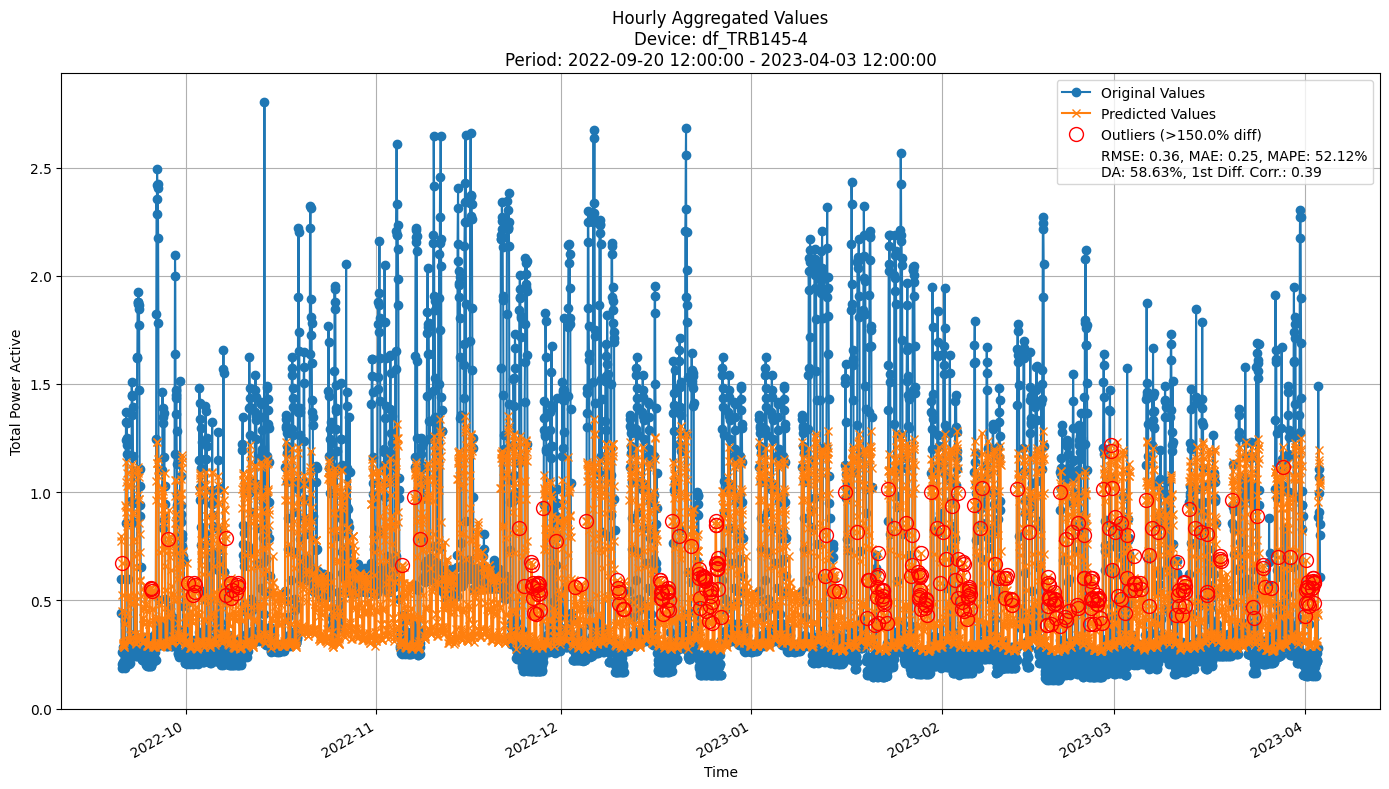

In [38]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

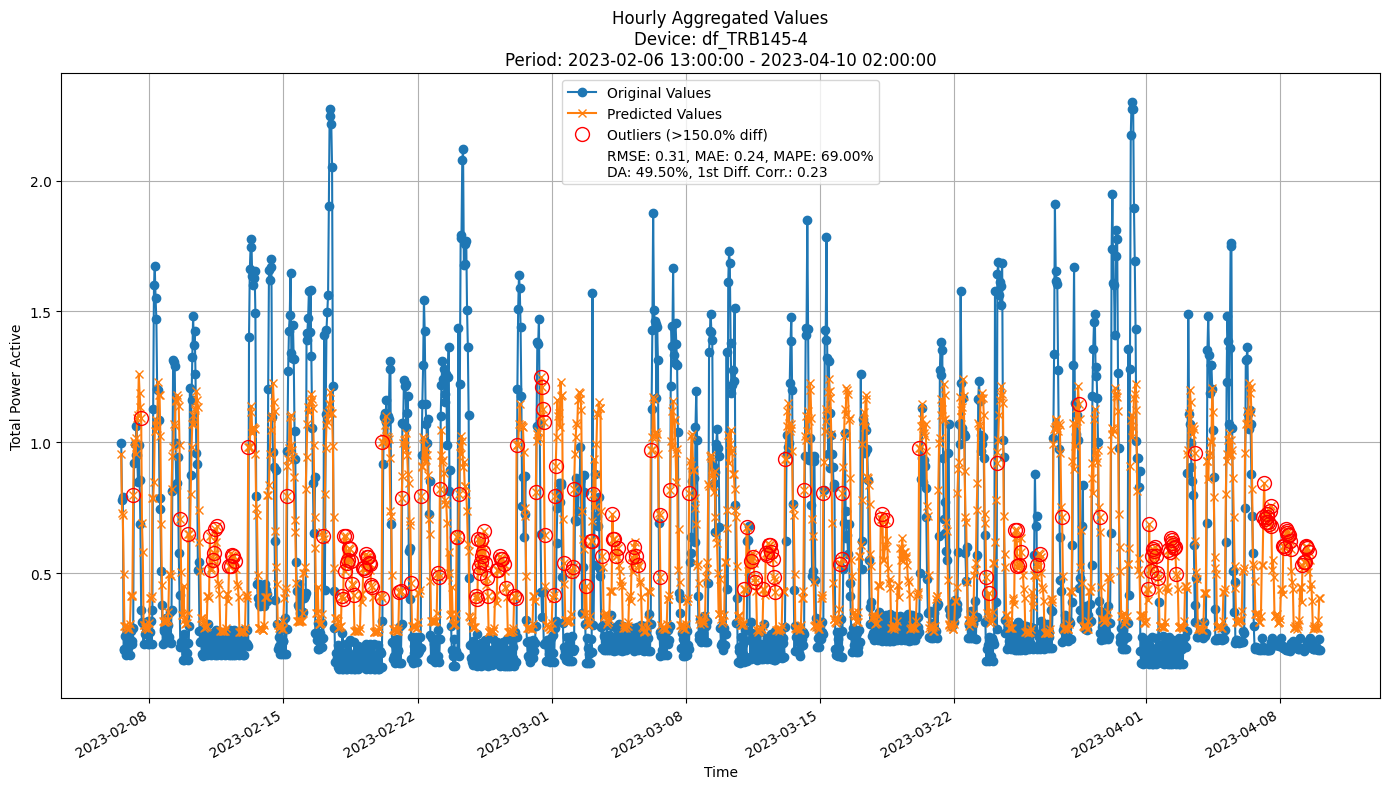

In [39]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

## Model Comparison

### Overall validation results

In [47]:
MODEL_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": all_time_valid_metrics,
}

AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]

device_ids = set()
for m in MODEL_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%)
0,Baseline,0.228 ± 0.041,0.129 ± 0.030,23.957 ± 7.384,39.392 ± 4.644,18.383 ± 19.704
1,GBDT,0.245 ± 0.062,0.170 ± 0.040,38.648 ± 6.302,61.142 ± 6.754,41.915 ± 10.446
2,RandomForest,0.222 ± 0.015,0.127 ± 0.009,22.147 ± 2.006,60.851 ± 2.981,48.586 ± 5.648
3,HoeffdingTree,0.293 ± 0.057,0.185 ± 0.043,33.554 ± 4.498,52.217 ± 3.570,31.919 ± 7.951
4,ARF_Hoeffding,0.265 ± 0.061,0.175 ± 0.042,36.376 ± 6.671,58.814 ± 4.784,45.298 ± 9.825
5,FastODT,0.429 ± 0.119,0.314 ± 0.076,65.440 ± 13.358,50.680 ± 2.863,20.277 ± 6.285
6,ARF_FastODT,0.390 ± 0.108,0.312 ± 0.079,79.597 ± 25.468,58.475 ± 3.606,48.041 ± 11.472
7,IncubationBoost,0.435 ± 0.139,0.314 ± 0.087,60.241 ± 12.651,57.207 ± 2.194,33.431 ± 6.990


### By-period validation results

In [52]:
MODEL_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, model_period_metrics, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        model_period_metrics: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in model_period_metrics.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [53]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=MODEL_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,36.066,55.589,55.887,45.306,52.161,49.329,55.440,54.545,50.540375
Period 2,38.301,56.036,53.800,52.012,57.973,48.435,57.526,57.824,52.738375
Period 3,50.224,71.833,54.545,54.247,64.083,52.906,65.276,59.762,59.109500
Period 4,38.152,67.362,57.526,53.502,62.593,53.353,62.146,55.440,56.259250
Period 5,35.469,67.064,57.526,53.651,63.785,52.757,58.420,54.844,55.439500
Period 6,37.407,54.694,54.993,49.478,51.863,52.757,55.738,57.526,51.807000
Period 7,40.127,55.414,43.949,57.325,59.236,45.223,54.777,60.510,52.070125



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,2.235,0.447,-2.087,6.706,5.812,-0.894,2.086,3.279,2.198
Period 3 - Period 2,11.923,15.797,0.745,2.235,6.110,4.471,7.750,1.938,6.371
Period 4 - Period 3,-12.072,-4.471,2.981,-0.745,-1.490,0.447,-3.130,-4.322,-2.850
Period 5 - Period 4,-2.683,-0.298,0.000,0.149,1.192,-0.596,-3.726,-0.596,-0.820
Period 6 - Period 5,1.938,-12.370,-2.533,-4.173,-11.922,0.000,-2.682,2.682,-3.633
Period 7 - Period 6,2.720,0.720,-11.044,7.847,7.373,-7.534,-0.961,2.984,0.263


#### MAPE (lower is better)

In [50]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=MODEL_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,17.404,27.653,21.210,29.104,27.374,40.131,38.300,41.565,30.342625
Period 2,23.446,42.626,29.953,33.072,39.912,59.556,86.161,53.160,45.985750
Period 3,19.005,34.157,26.747,28.871,25.597,61.985,86.561,46.945,41.233500
Period 4,31.500,48.706,36.120,37.726,38.402,76.949,122.735,76.837,58.621875
Period 5,32.715,42.714,39.497,40.443,45.128,77.228,97.601,74.554,56.235000
Period 6,31.064,37.484,32.339,36.940,37.358,60.485,63.778,60.360,44.976000
Period 7,12.564,37.197,21.602,28.721,40.861,81.749,62.044,68.263,44.125125



Absolute gain/drop in MAPE (%) (lower is better):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.042,14.973,8.743,3.968,12.538,19.425,47.861,11.595,15.643
Period 3 - Period 2,-4.441,-8.469,-3.206,-4.201,-14.315,2.429,0.400,-6.215,-4.752
Period 4 - Period 3,12.495,14.549,9.373,8.855,12.805,14.964,36.174,29.892,17.388
Period 5 - Period 4,1.215,-5.992,3.377,2.717,6.726,0.279,-25.134,-2.283,-2.387
Period 6 - Period 5,-1.651,-5.230,-7.158,-3.503,-7.770,-16.743,-33.823,-14.194,-11.259
Period 7 - Period 6,-18.500,-0.287,-10.737,-8.219,3.503,21.264,-1.734,7.903,-0.851


#### RMSE (lower is better)

In [51]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=MODEL_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.253,0.348,0.324,0.375,0.363,0.550,0.511,0.600,0.415500
Period 2,0.258,0.308,0.287,0.357,0.325,0.590,0.551,0.630,0.413250
Period 3,0.178,0.185,0.185,0.235,0.180,0.360,0.321,0.357,0.250125
Period 4,0.271,0.269,0.269,0.289,0.271,0.553,0.453,0.541,0.364500
Period 5,0.236,0.214,0.246,0.296,0.275,0.343,0.351,0.336,0.287125
Period 6,0.245,0.226,0.239,0.299,0.250,0.316,0.308,0.307,0.273750
Period 7,0.154,0.165,0.156,0.199,0.190,0.292,0.234,0.273,0.207875



Absolute gain/drop in RMSE (lower is better):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.005,-0.040,-0.037,-0.018,-0.038,0.040,0.040,0.030,-0.002
Period 3 - Period 2,-0.080,-0.123,-0.102,-0.122,-0.145,-0.230,-0.230,-0.273,-0.163
Period 4 - Period 3,0.093,0.084,0.084,0.054,0.091,0.193,0.132,0.184,0.114
Period 5 - Period 4,-0.035,-0.055,-0.023,0.007,0.004,-0.210,-0.102,-0.205,-0.077
Period 6 - Period 5,0.009,0.012,-0.007,0.003,-0.025,-0.027,-0.043,-0.029,-0.013
Period 7 - Period 6,-0.091,-0.061,-0.083,-0.100,-0.060,-0.024,-0.074,-0.034,-0.066
